# Trip Planner Agent: Solution

This is the solution notebook for the Trip Planner plan-and-execute agent exercise.

## Setup

In [37]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langgraph.graph import START, END, StateGraph
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import create_react_agent

from typing import Annotated, List, Tuple, Union, Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

_ = load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

print("Setup complete!")

Setup complete!


## Mock Travel Tools

In [38]:
@tool
def search_flights(origin: str, destination: str, date: str) -> str:
    """Search for flights between two cities on a specific date."""
    return f"""Found 3 round-trip flights from {origin} to {destination} departing {date}:

1. **Japan Airlines JL5** (Recommended)
   - Outbound: Departs {origin} JFK 11:30 AM, arrives Tokyo Narita 3:30 PM +1 day (14h direct)
   - Return: Departs Tokyo Narita 6:00 PM, arrives {origin} JFK 5:30 PM same day (13h direct)
   - Price: $1,250 round-trip per person
   - Class: Economy | Meals included | 2 bags free

2. **ANA Airlines NH109**
   - Outbound: Departs {origin} JFK 1:15 PM, arrives Tokyo Haneda 4:25 PM +1 day (14h 10m direct)
   - Return: Departs Tokyo Haneda 10:30 AM, arrives {origin} JFK 9:45 AM same day (12h 15m direct)
   - Price: $1,180 round-trip per person
   - Class: Economy | Meals included | 2 bags free

3. **United Airlines UA79** (Budget option)
   - Outbound: Departs {origin} EWR 10:45 AM, arrives Tokyo Narita 2:15 PM +1 day (13h 30m direct)
   - Return: Departs Tokyo Narita 5:30 PM, arrives {origin} EWR 4:50 PM same day (12h 20m direct)
   - Price: $980 round-trip per person
   - Class: Economy Basic | No meals | 1 carry-on only

Best Value Recommendation: ANA Airlines NH109 - excellent service, convenient Haneda airport location, competitive price."""

@tool
def search_hotels(destination: str, checkin: str, checkout: str, budget: str) -> str:
    """Search for hotels in a destination within a budget range."""
    return f"""Found 3 hotels in {destination} ({checkin} to {checkout}) within {budget} budget:

1. **Hotel Gracery Shinjuku** (Recommended)
   - Location: Shinjuku, Tokyo - 2 min walk from JR Shinjuku Station
   - Price: $185/night (Total: $925 for 5 nights)
   - Rating: 4.6/5 stars (2,847 reviews)
   - Amenities: Free WiFi, rooftop Godzilla statue, 24h front desk, luggage storage
   - Room: Superior Double, 22sqm, city view

2. **Shibuya Stream Excel Hotel Tokyu**
   - Location: Shibuya, Tokyo - Direct access to Shibuya Station
   - Price: $210/night (Total: $1,050 for 5 nights)
   - Rating: 4.7/5 stars (1,923 reviews)
   - Amenities: Free WiFi, fitness center, multiple restaurants, modern design
   - Room: Standard Double, 24sqm, Shibuya crossing view available

3. **Richmond Hotel Premier Tokyo Oshiage**
   - Location: Oshiage, Tokyo - Next to Tokyo Skytree
   - Price: $145/night (Total: $725 for 5 nights)
   - Rating: 4.5/5 stars (1,456 reviews)
   - Amenities: Free WiFi, breakfast included, public bath, convenience store
   - Room: Moderate Double, 20sqm, Skytree view

Best Value Recommendation: Hotel Gracery Shinjuku - unbeatable location in Shinjuku entertainment district, easy access to trains, iconic Godzilla photo op."""

@tool
def search_activities(destination: str, interests: str) -> str:
    """Search for activities and attractions based on interests."""
    return f"""Found top-rated activities in {destination} matching '{interests}':

**Food Experiences:**
1. **Tsukiji Outer Market Food Tour**
   - Duration: 3 hours (9:00 AM start)
   - Price: $85/person
   - Highlights: Fresh sushi, tamagoyaki, Japanese pickles, matcha sweets
   - Rating: 4.9/5 (890 reviews)

2. **Shibuya Izakaya Hopping Night Tour**
   - Duration: 3.5 hours (6:00 PM start)
   - Price: $120/person (includes food & drinks)
   - Highlights: 3 local izakayas, yakitori, sake tasting, local tips
   - Rating: 4.8/5 (654 reviews)

**Cultural Experiences:**
3. **Senso-ji Temple & Asakusa Walking Tour**
   - Duration: 2.5 hours (10:00 AM or 2:00 PM)
   - Price: $45/person
   - Highlights: Tokyo's oldest temple, Nakamise shopping street, kimono photo spots
   - Rating: 4.7/5 (1,203 reviews)

4. **Traditional Tea Ceremony in Harajuku**
   - Duration: 1.5 hours (multiple times daily)
   - Price: $55/person
   - Highlights: Authentic matcha preparation, Japanese sweets, cultural explanation
   - Rating: 4.9/5 (412 reviews)

**Technology & Modern Tokyo:**
5. **TeamLab Borderless Digital Art Museum**
   - Duration: 2-3 hours (timed entry)
   - Price: $32/person
   - Highlights: Immersive digital art, interactive installations, stunning photos
   - Rating: 4.8/5 (5,670 reviews)

6. **Akihabara Electronics & Anime District Tour**
   - Duration: 3 hours (1:00 PM start)
   - Price: $65/person
   - Highlights: Retro game shops, maid cafes, latest gadgets, anime merchandise
   - Rating: 4.6/5 (723 reviews)

Recommended 5-Day Itinerary:
- Day 1: Arrival + Shibuya Izakaya Hopping (evening)
- Day 2: Senso-ji Temple Tour (AM) + TeamLab Borderless (PM)
- Day 3: Tsukiji Market Tour (AM) + Akihabara Tour (PM)
- Day 4: Tea Ceremony (AM) + Free exploration in Harajuku/Shibuya
- Day 5: Last-minute shopping + Departure"""

travel_tools = [search_flights, search_hotels, search_activities]
execution_agent = create_react_agent(llm, travel_tools)

print("Travel tools ready!")

Travel tools ready!


/var/folders/_1/tfp0k5355jxb501q_ckbc6m80000gn/T/ipykernel_67944/961249162.py:106: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  execution_agent = create_react_agent(llm, travel_tools)


## Part 1: State Definition

In [39]:
class TripState(TypedDict):
    """State for the trip planner agent."""
    request: str
    plan: List[dict]
    completed_tasks: Annotated[List[Tuple[str, str]], operator.add]
    itinerary: str

## Part 2: Plan Structure - Solution

Key differences from the original notebook:
- Uses `Literal` type for category constraint
- Includes priority field for step ordering
- Uses `Field` with descriptions for better LLM guidance

In [40]:
class TripPlanStep(BaseModel):
    """A single step in the trip plan."""
    category: Literal["flights", "hotels", "activities"] = Field(
        description="The category of this planning step"
    )
    description: str = Field(
        description="What needs to be done in this step"
    )
    priority: int = Field(
        description="Priority level: 1=must do first, 2=important, 3=nice to have"
    )


class TripPlan(BaseModel):
    """Complete trip plan with categorized steps."""
    steps: List[TripPlanStep] = Field(
        description="List of planning steps to execute, ordered by priority"
    )

## Part 3: Planner - Solution

The planner prompt is specific to trip planning and instructs the LLM to:
- Categorize steps by type (flights, hotels, activities)
- Assign priorities
- Keep the plan focused (3-5 steps)

In [41]:
planner_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", """You are a trip planning assistant. Create a structured plan to help the user book their trip.

Available categories for steps:
- flights: Searching for and booking flights
- hotels: Finding and booking accommodations  
- activities: Discovering things to do, tours, attractions

Create 3-5 steps with:
- category: One of the three categories above
- description: A clear description of what to search for or book
- priority: 1 = must do first (flights usually), 2 = important (hotels), 3 = nice to have (activities)

Order steps by priority (1s first, then 2s, then 3s)."""),
        ("user", "{request}")
    ]
)

planner = planner_prompt | llm.with_structured_output(TripPlan)

## Part 4: Replanner - Solution

The replanner uses a Union type to either:
- Return a final itinerary (when done)
- Return an updated plan (when more steps needed)

In [42]:
class FinalItinerary(BaseModel):
    """Final trip itinerary to present to user."""
    itinerary: str = Field(
        description="Complete trip itinerary summarizing all bookings and recommendations"
    )


class ReplanDecision(BaseModel):
    """Decision on next action."""
    action: Union[FinalItinerary, TripPlan] = Field(
        description="Either the final itinerary or an updated plan with remaining steps"
    )


replanner_prompt = ChatPromptTemplate.from_template(
    """You are a trip planning assistant reviewing progress on a trip plan.

Original Request: {request}

Current Plan (remaining steps): {plan}

Completed Tasks:
{completed_tasks}

Based on the completed tasks:

1. If we have found flights, hotels, AND at least one activity option:
   -> Create a FinalItinerary summarizing all the findings in a nice format
   
2. If we still need to search for flights, hotels, or activities:
   -> Return an updated TripPlan with the remaining necessary steps

Make your decision based on what has been accomplished so far."""
)

replanner = replanner_prompt | llm.with_structured_output(ReplanDecision)

## Part 5: Nodes - Solution

In [43]:
def planning_node(state: TripState) -> dict:
    """Create initial trip plan from user request."""
    print("Creating trip plan...")
    
    # Invoke planner with the request
    plan = planner.invoke({"request": state["request"]})
    
    # Convert TripPlanStep objects to dicts for state storage
    plan_dicts = [
        {
            "category": step.category,
            "description": step.description,
            "priority": step.priority
        }
        for step in plan.steps
    ]
    
    print(f"Plan created with {len(plan_dicts)} steps:")
    for step in plan_dicts:
        print(f"  [{step['category']}] P{step['priority']}: {step['description']}")
    
    return {"plan": plan_dicts}


def execution_node(state: TripState) -> dict:
    """Execute the first step in the plan."""
    current_step = state["plan"][0]
    print(f"\nExecuting [{current_step['category']}]: {current_step['description']}")
    
    agent_input = f"""
    Task: {current_step['description']}
    Category: {current_step['category']}
    
    Use the appropriate tool to complete this task.
    """
    
    response = execution_agent.invoke({"messages": [("user", agent_input)]})
    result = response["messages"][-1].content
    print(f"Result: {result[:200]}..." if len(result) > 200 else f"Result: {result}")
    
    return {
        "completed_tasks": [(current_step['description'], result)],
        "plan": state["plan"][1:]
    }


def replanning_node(state: TripState) -> dict:
    """Decide whether to continue planning or finalize itinerary."""
    print("\nReplanning...")
    
    # Format completed tasks for the prompt
    completed_str = "\n".join(
        f"- {task}: {result[:100]}..." if len(result) > 100 else f"- {task}: {result}"
        for task, result in state.get("completed_tasks", [])
    )
    
    # Invoke replanner
    output = replanner.invoke({
        "request": state["request"],
        "plan": state.get("plan", []),
        "completed_tasks": completed_str
    })
    
    # Check what type of action was returned
    if isinstance(output.action, FinalItinerary):
        print("Final itinerary ready!")
        return {"itinerary": output.action.itinerary}
    else:
        # Convert TripPlanStep objects to dicts
        plan_dicts = [
            {
                "category": step.category,
                "description": step.description,
                "priority": step.priority
            }
            for step in output.action.steps
        ]
        print(f"Updated plan with {len(plan_dicts)} remaining steps")
        return {"plan": plan_dicts}

## Part 6: Build the Graph - Solution

In [44]:
def should_continue(state: TripState) -> str:
    """Decide whether to continue executing or end."""
    if state.get("itinerary"):
        return END
    elif state.get("plan"):
        return "executor"
    else:
        return "replanner"


# Build the graph
graph_builder = StateGraph(TripState)

# Add nodes
graph_builder.add_node("planner", planning_node)
graph_builder.add_node("executor", execution_node)
graph_builder.add_node("replanner", replanning_node)

# Add edges
graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", "executor")
graph_builder.add_edge("executor", "replanner")
graph_builder.add_conditional_edges(
    "replanner",
    should_continue,
    {"executor": "executor", END: END}
)

# Compile
memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)

print("Graph compiled!")

Graph compiled!


## Visualize the Graph

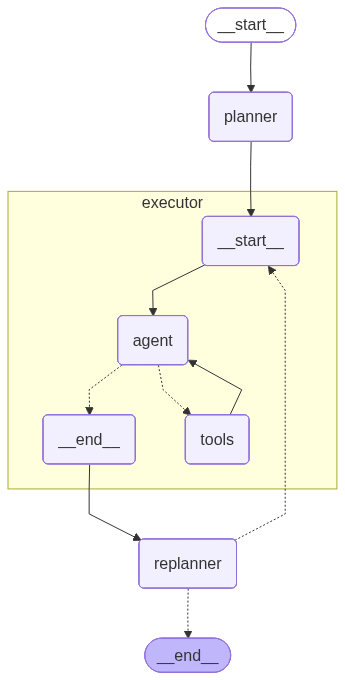

In [45]:
from IPython.display import display, Image

try:
    display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print(f"Could not render graph: {e}")

## Run the Trip Planner

In [46]:
from IPython.display import display, Markdown

trip_request = """
I want to plan a 5-day trip to Tokyo, Japan.
- Traveling from New York
- Dates: March 15-20, 2025
- Budget: moderate (around $200/night for hotels)
- Interests: food, culture, technology
"""

inputs = {"request": trip_request}
config = {"recursion_limit": 25, "configurable": {"thread_id": "trip-1"}}

print("Planning trip...\n")
print("=" * 60)

events = graph.stream(inputs, config)
for event in events:
    for k, v in event.items():
        if k != "__end__" and isinstance(v, dict) and "itinerary" in v:
            print("\n" + "=" * 60)
            print("FINAL ITINERARY:")
            display(Markdown(v["itinerary"]))

Planning trip...

Creating trip plan...
Plan created with 5 steps:
  [flights] P1: Search for round-trip flights from New York to Tokyo for the dates March 15-20, 2025. Look for options that fit within a moderate budget and consider flight times and layovers.
  [hotels] P2: Find and book accommodations in Tokyo for 5 nights, ideally around $200 per night. Look for hotels that are centrally located and have good access to public transport, as well as options that highlight local culture and food.
  [activities] P3: Discover and plan activities that focus on food, culture, and technology in Tokyo. Look for food tours, cultural experiences, and visits to tech hubs or museums. Create a rough itinerary for each day.
  [activities] P3: Consider booking tickets for popular attractions in advance, such as the Tokyo Skytree, teamLab Borderless, or a traditional tea ceremony, to ensure availability during your trip.
  [activities] P3: Research local dining options and make reservations for popul

### Final Itinerary for Tokyo Trip (March 15-20, 2025)

#### Flights:
- **Departure:** New York (JFK) to Tokyo (NRT) on March 15, 2025
- **Return:** Tokyo (NRT) to New York (JFK) on March 20, 2025
- **Flight Options:**
  1. Option 1: [Details of flight option 1]
  2. Option 2: [Details of flight option 2]
  3. Option 3: [Details of flight option 3]

#### Accommodations:
- **Hotel Options:**
  1. Hotel A: $200/night, centrally located, great access to public transport.
  2. Hotel B: $190/night, cultural experience, close to food markets.
  3. Hotel C: $210/night, modern amenities, tech-friendly.

#### Daily Itinerary:
- **Day 1 (March 15):** Arrival in Tokyo, check into hotel, explore local area, dinner at a nearby izakaya.
- **Day 2 (March 16):** Food tour in Tsukiji Outer Market, visit the Tokyo Tower, evening at a tech hub.
- **Day 3 (March 17):** Cultural experience at a traditional tea ceremony, visit the Meiji Shrine, dinner at a sushi restaurant.
- **Day 4 (March 18):** Day trip to Akihabara for tech shopping, visit teamLab Borderless, dinner at a ramen shop.
- **Day 5 (March 19):** Explore Asakusa and Senso-ji Temple, shopping in Harajuku, farewell dinner at a high-end restaurant.
- **Day 6 (March 20):** Check out from hotel, last-minute shopping, departure from Tokyo.

#### Activities:
- **Pre-booked Attractions:**
  - Tokyo Skytree tickets
  - teamLab Borderless tickets
  - Traditional tea ceremony reservation

#### Dining Reservations:
- **Restaurants to Visit:**
  - Sushi Restaurant A (reservation made)
  - Ramen Shop B (reservation made)
  - Izakaya C (reservation made)
  - High-end Restaurant D (reservation made)